# Quan Mai — k-NN and clustering

**Six steps:** 
load data → implement k-NN → compare all five preprocessing methods and k-NN settings → present the best setups → predict test labels → cluster images and sentiment.

Both algorithms are implemented with NumPy. Scikit-learn supplies only splitting,

PCA preprocessing, and evaluation.



## 1. Data and the shared validation split
Keep CSV row order and use the team's stratified **80/20 split, seed 42**. Package versions are printed for reproducibility.

In [1]:
# Libraries for data handling, plots, preprocessing, and evaluation.
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

# Use the same random seed as teammates; later, compare 128 queries at a time.
SEED, BATCH_SIZE = 42, 128
threadpool_limits(limits=4)  # Limit numerical operations to four CPU threads.

# This fixed folder contains the four train/test CSV paths
DATA_DIR = Path('/kaggle/input/competitions/comp-472-project-fall-2026-concordia')
OUTPUT_DIR = Path('/kaggle/working/part_b')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Create the folder for exported results.
print(f'NumPy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}')

# Images have 500 features and 50 classes; sentiment has 768 features and 3 classes.
data = {}
for task, width, classes in [('image', 500, 50), ('sentiment', 768, 3)]:
    # Read the task's train/test files. Keep sample IDs as text.
    train = pd.read_csv(DATA_DIR / f'{task}_train.csv', dtype={'id': 'string'})
    test = pd.read_csv(DATA_DIR / f'{task}_test.csv', dtype={'id': 'string'})

    features = [f'feature_{i}' for i in range(width)]
    # Select only feature columns and convert them into NumPy arrays of decimal numbers.
    X, X_test = train[features].to_numpy(float), test[features].to_numpy(float)

    # Split labeled rows into 80% training / 20% validation without sorting the CSV.
    # Stratification preserves class proportions
    # This returns 2 groups of row positions. E.g: train_idx = [7, 2, 9, ...]
    train_idx, val_idx = train_test_split(range(len(train)), test_size=0.2,
                                         random_state=SEED, stratify=train['label'])

    # Store features (X), labels (y), test IDs, and row indices for later steps.
    data[task] = dict(X=X, y=train['label'].to_numpy(int), X_test=X_test,
                      test_ids=test['id'], train_idx=train_idx, val_idx=val_idx, classes=classes)
    print(f'{task}: {len(train_idx)} train / {len(val_idx)} validation / {len(test)} test')

NumPy 2.5.4; pandas 3.1.1; scikit-learn 1.9.1


image: 16000 train / 4000 validation / 5000 test


sentiment: 9600 train / 2400 validation / 5000 test


## 2. k-NN from scratch
For each query: **calculate distances → select k closest training rows → vote**.

Distance functions: 
- **Euclidean distance**  (distance² = sum(a²) + sum(b²) − 2 × dot_product(a, b))  compares vector **magnitudes and directions** VS **cosine** compares **directions**.

Voting: 
- **Uniform voting (unweighted voting)** counts **neighbors** VS **Distance voting** gives **nearer neighbors** more weight;

if exact matches exist, only they vote. Ties use training-row order, then the smallest class label.

Feature normalization choices:
- **Raw:** use the original feature values.
- **Standardization:** subtract each feature's training mean and divide by its training standard deviation.
- **L2 normalization:** divide each example by its length, so each nonzero example has length 1.

Standardization rescales **columns (features)**; L2 normalization rescales **rows (examples)**.
Use the training mean and standard deviation for validation and test data too.

In [2]:
# L2 normalization: divide each example by its length, so each nonzero example has length 1.
def normalize(X):
    lengths = np.linalg.norm(X, axis=1, keepdims=True)  # Euclidean distance 
    return np.divide(X, lengths, out=np.zeros_like(X), where=lengths > 0) 

# train_X - features from the training portion
# query_X - features we want to classify
def preprocess(train_X, query_X, method):
    if method == 'standard':
        mean, scale = train_X.mean(0), train_X.std(0) # calculate the mean and S.D of each feature 
        scale[scale == 0] = 1 #if S.D == 0, make it 1 => avoid division by 0 error 
        return (train_X - mean) / scale, (query_X - mean) / scale
    elif method == 'l2':
        return normalize(train_X), normalize(query_X)
    elif method == 'raw':
        return train_X, query_X
    else:
        raise ValueError(f"Unknown preprocessing method: {method}")


def distances(A, B, metric):
    if metric == 'cosine':
        result = np.clip(1 - normalize(A) @ normalize(B).T, 0, 2)
        result[result < 1e-12] = 0
        return result
    elif metric == 'euclidean':
        norm_sum = (A*A).sum(1)[:, None] + (B*B).sum(1)[None, :]
        squared = norm_sum - 2 * A @ B.T
        # If a result is so close to zero that it could just be computer rounding, make it zero.
        squared[np.abs(squared) <= 16*np.finfo(float).eps*np.maximum(norm_sum, 1)] = 0
        return np.sqrt(np.maximum(squared, 0))

def nearest_neighbors(train_X, query_X, k, metric):
    # Batching avoids a full query-count × training-count distance matrix. => reduce memory needed 
    assert 1 <= k <= len(train_X)
    all_distances, all_indices = [], []
    for start in range(0, len(query_X), BATCH_SIZE):
        # calculates distances from the current group to every training example. 128 query examples × 16,000 training examples = 2,048,000 distances
        d = distances(query_X[start:start+BATCH_SIZE], train_X, metric)
        # returns positions ordered from smallest distance to largest
        indices = np.argsort(d, axis=1, kind='stable')[:, :k].copy()
        all_indices.append(indices) # collect the neighbor positions
        all_distances.append(np.take_along_axis(d, indices, axis=1)) # retrieves the values at the selected positions
#     # First returned array: neighbor distances
# [
#     [0.2, 0.5],   # Query 0
#     [0.1, 0.3],   # Query 1
#     [0.4, 0.6],   # Query 2
# ]

# # Second returned array: neighbor positions in train_X
# [
#     [7, 12],      # Query 0's neighbors are training rows 7 and 12
#     [3,  8],      # Query 1's neighbors are training rows 3 and 8
#     [2, 15],      # Query 2's neighbors are training rows 2 and 15
# ]
    return np.vstack(all_distances), np.vstack(all_indices)

def vote(train_y, neighbor_distances, neighbor_indices, k, voting, classes):
    # selects the first k neighbors and looks up their labels
    labels, d = train_y[neighbor_indices[:, :k]], neighbor_distances[:, :k]
    weights = np.ones_like(d) # Make an array w/ the same shape as d, and fill it with "1" -> Unweighted voting 
    if voting == 'distance':
        exact = d == 0 # Check every distance in d if it's equal to zero
        weights = 1 / np.maximum(d, 1e-12) # gives closer distance higher weight
        weights = np.where(exact.any(1, keepdims=True), exact.astype(float), weights) #  with zero-distance neighbors ( use 1/0), rows without zero-distance neighbors: keep the existing inverse-distance weights
    scores = np.zeros((len(labels), classes))
    for label in range(classes):
        scores[:, label] = (weights * (labels == label)).sum(1) # Add up the votes for this class and return its score
    return scores.argmax(1) # Return the class with the most votes

## 3. Compare k-NN configurations on both datasets

We vary **k, distance (Euclidean/cosine), preprocessing, and voting (uniform/distance-weighted)**.
On top of the 3 preprocessing methods used above, we also test with ****Square-root + L2** &  **PCA whitening** using the same training/validation rows and k-NN search grid:

- **Square-root + L2:** apply `sign(x) * sqrt(abs(x))`, then normalize each row to length 1.
  Image features are nonnegative, so this is ordinary square-root preprocessing.
  Sentiment features include negatives, so the signed version preserves their signs.
- **PCA whitening (256):** learn PCA directions from the training portion, retain 256 components,
  and whitening rescales them to unit training variance. Transform validation rows using the fitted PCA.
  Scikit-learn supplies PCA preprocessing;

- **Images:** 5 k values × 2 distances × 5 preprocessing methods × 2 voting choices = **100 configurations**.
- **Sentiment:** 12 k values × 2 distances × 5 preprocessing methods × 2 voting choices = **240 configurations**.

**Table 1** shows the best configuration for each preprocessing method and dataset (**10 rows**).
**Figure 1** plots these results without repeating the experiments.
Section 4 presents the overall winners.

The winning score is **validation accuracy used for tuning**.
PCA whitening here combines dimensionality reduction and whitening; both its 256 components
and the square-root exponent of 0.5 are fixed rather than tuned.


In [3]:
from IPython.display import Markdown

def show_table(table, title, formats=None):
    display(Markdown(f'### {title}'))
    display(table.style.format(formats or {}).hide(axis='index'))

from sklearn.decomposition import PCA

def comparison_preprocess(train_X, val_X, method):
    if method in ['raw', 'standard', 'l2']:
        return preprocess(train_X, val_X, method)
    if method == 'Square-root + L2':
        # This same formula handles nonnegative image features and signed sentiment features.
        train_root = np.sign(train_X) * np.sqrt(np.abs(train_X))
        val_root = np.sign(val_X) * np.sqrt(np.abs(val_X))
        return normalize(train_root), normalize(val_root)
    if method == 'PCA whitening (256)':
        # Learn PCA directions and whitening scales only from the training portion.
        pca = PCA(n_components=256, whiten=True, svd_solver='full')
        return pca.fit_transform(train_X), pca.transform(val_X)
    raise ValueError(f'Unknown preprocessing method: {method}')

METHODS = {'image': ['raw', 'standard', 'l2', 'Square-root + L2', 'PCA whitening (256)'],
           'sentiment': ['raw', 'standard', 'l2', 'Square-root + L2', 'PCA whitening (256)']}
K_VALUES = {'image': [1, 3, 5, 10, 20],
            'sentiment': [1, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 4000]}


In [4]:
records, best, validation_predictions = [], {}, {}
for task, ds in data.items():
    ti, vi = ds['train_idx'], ds['val_idx']
    for method in METHODS[task]:
        train_X, val_X = comparison_preprocess(ds['X'][ti], ds['X'][vi], method)
        for metric in ['euclidean', 'cosine']:
            start = time.perf_counter()
            d, idx = nearest_neighbors(train_X, val_X, max(K_VALUES[task]), metric)
            search_seconds = time.perf_counter() - start
            for k in K_VALUES[task]:
                for voting in ['uniform', 'distance']:
                    pred = vote(ds['y'][ti], d, idx, k, voting, ds['classes'])
                    accuracy = np.mean(pred == ds['y'][vi])
                    record = dict(task=task, preprocessing=method, metric=metric, k=k,
                                  voting=voting, accuracy=accuracy, shared_search_seconds=search_seconds)
                    records.append(record)
                    # First encountered setting wins an exact accuracy tie.
                    if task not in best or accuracy > best[task]['accuracy']:
                        best[task], validation_predictions[task] = record.copy(), pred.copy()
        print(f'{task}: finished {method}', flush=True)

results = pd.DataFrame(records)

# Rank all five methods together; retain the first encountered setting on an accuracy tie.
comparison_trials = results.rename(columns={'preprocessing': 'comparison_method'}).drop(columns='shared_search_seconds')
comparison_tuned = comparison_trials.sort_values('accuracy', ascending=False, kind='stable').drop_duplicates(
    ['task', 'comparison_method']).copy()

columns = ['task', 'comparison_method', 'k', 'metric', 'voting', 'accuracy']
show_table(comparison_tuned.sort_values(['task', 'accuracy'], ascending=[True, False])[columns],
           'Table 1. Best k-NN configuration for each of the five preprocessing methods',
           {'accuracy': '{:.3%}'})


image: finished raw


image: finished standard


image: finished l2


image: finished Square-root + L2


image: finished PCA whitening (256)


sentiment: finished raw


... (2 outputs left out)

sentiment: finished Square-root + L2


sentiment: finished PCA whitening (256)


### Table 1. Best k-NN configuration for each of the five preprocessing methods

task,comparison_method,k,metric,voting,accuracy
image,Square-root + L2,1,euclidean,uniform,57.175%
image,standard,1,cosine,uniform,53.400%
image,raw,1,euclidean,uniform,53.075%
image,l2,1,euclidean,uniform,53.075%
image,PCA whitening (256),1,cosine,uniform,47.625%
sentiment,PCA whitening (256),4000,cosine,distance,65.500%
sentiment,standard,100,cosine,distance,58.417%
sentiment,raw,100,cosine,distance,58.375%
sentiment,l2,100,cosine,distance,58.375%
sentiment,Square-root + L2,100,cosine,distance,57.542%


### Effect of k across all five preprocessing methods
The curves show how changing k affects the best distance/voting setting for each method.

k-NN stores the training examples instead of learning weights. Accuracy on those
same examples can be misleading because each query can retrieve itself, so the
comparison below uses the separate validation rows.

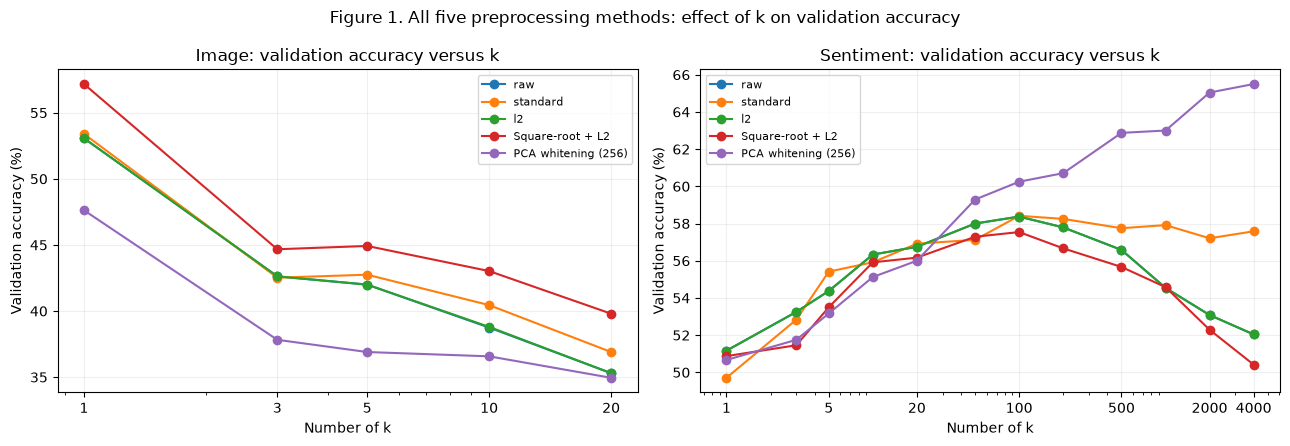

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, task in zip(axes, data):
    for method in METHODS[task]:
        subset = results[(results.task == task) & (results.preprocessing == method)]
        winner = subset.loc[subset.accuracy.idxmax()]
        curve = subset[(subset.metric == winner.metric) & (subset.voting == winner.voting)]
        ax.plot(curve.k, 100 * curve.accuracy, 'o-', label=method)
    ticks = [1, 3, 5, 10, 20] if task == 'image' else [1, 5, 20, 100, 500, 2000, 4000]
    ax.set_xscale('log')
    ax.set_xticks(ticks, labels=[str(k) for k in ticks])
    ax.set(title=f'{task.capitalize()}: validation accuracy versus k',
           xlabel='Number of k', ylabel='Validation accuracy (%)')
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
fig.suptitle('Figure 1. All five preprocessing methods: effect of k on validation accuracy')
fig.tight_layout()
plt.show()


## 4. Best setup for each dataset
Use the results already calculated in Section 3 to select the **overall winner for each dataset**.
This section does not run additional experiments.

**Table 2** reports the winning preprocessing, k, distance, voting, and validation accuracy.
**Figure 2** compares all five methods' best accuracies and annotates the winning settings.
Tables and plots are displayed in the notebook.

These scores come from the fixed **20% validation sets** used for tuning; hidden-test accuracy is unknown.
Each preprocessing method can choose its own k, distance, and voting, so the results reflect the complete setup.


### Table 2. Overall best tested k-NN setup for each dataset

task,comparison_method,k,metric,voting,accuracy
image,Square-root + L2,1,euclidean,uniform,57.175%
sentiment,PCA whitening (256),4000,cosine,distance,65.500%


Mean image/sentiment validation accuracy: 61.337%


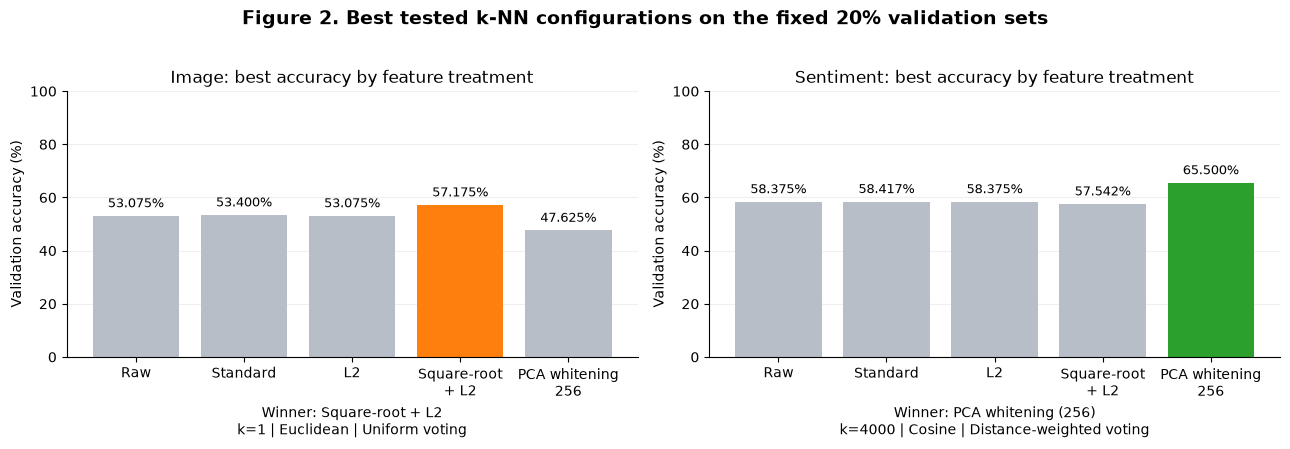

### Error summary for the overall winners

image: most common error is true class 37 predicted as 38: 9 examples.
sentiment: most common error is true class 1 predicted as 0: 217 examples.


In [6]:
# Select winners from the existing results; no distances are recomputed here.
overall_winners = pd.DataFrame(best.values()).rename(
    columns={'preprocessing': 'comparison_method'}).drop(columns='shared_search_seconds').sort_values('task')
final_best = {row['task']: row for row in overall_winners.to_dict('records')}
show_table(overall_winners[columns], 'Table 2. Overall best tested k-NN setup for each dataset',
           {'accuracy': '{:.3%}'})
print(f'Mean image/sentiment validation accuracy: {overall_winners.accuracy.mean():.3%}')

method_order = METHODS['image']
method_labels = ['Raw', 'Standard', 'L2', 'Square-root\n+ L2', 'PCA whitening\n256']
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, task in zip(axes, ['image', 'sentiment']):
    scores = comparison_tuned[comparison_tuned.task == task].set_index('comparison_method').loc[method_order].accuracy
    winner = final_best[task]
    winning_position = method_order.index(winner['comparison_method'])
    colors = ['#b8bec7'] * len(method_order)
    colors[winning_position] = 'tab:orange' if task == 'image' else 'tab:green'
    bars = ax.bar(range(len(method_order)), 100 * scores.to_numpy(), color=colors)
    ax.bar_label(bars, labels=[f'{score:.3%}' for score in scores], padding=4, fontsize=9)
    ax.set(title=f'{task.capitalize()}: best accuracy by feature treatment',
           ylabel='Validation accuracy (%)', ylim=(0, 100),
           xticks=range(len(method_order)), xticklabels=method_labels)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
    voting_label = 'Uniform voting' if winner['voting'] == 'uniform' else 'Distance-weighted voting'
    ax.text(.5, -.18, f"Winner: {winner['comparison_method']}\n"
            f"k={int(winner['k'])} | {winner['metric'].capitalize()} | {voting_label}",
            transform=ax.transAxes, ha='center', va='top', fontsize=10)
fig.suptitle('Figure 2. Best tested k-NN configurations on the fixed 20% validation sets',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, .12, 1, .96])
plt.show()

# Brief error analysis of the final winners
display(Markdown('### Error summary for the overall winners'))
for task, ds in data.items():
    truth, pred = ds['y'][ds['val_idx']], validation_predictions[task]
    errors = pd.DataFrame({'true': truth[truth != pred], 'predicted': pred[truth != pred]})
    error_pairs = errors.value_counts().rename('count').reset_index()
    if len(error_pairs):
        pair = error_pairs.iloc[0]
        print(f"{task}: most common error is true class {int(pair['true'])} predicted as "
              f"{int(pair['predicted'])}: {int(pair['count'])} examples.")


## 5. Predict labels for the competition’s test files
Use the overall winners from Section 4. Refit preprocessing on **all labeled rows** and export
5,000 candidate predictions for each task. Keep each prediction paired with its own test ID.
The team chooses its winning model separately for images and sentiment.

The optional combined CSV is disabled until the team selects k-NN for both tasks.
If another member wins a task, replace that task's table with their `id,label` CSV
before using `make_submission`.

In [7]:
predictions = {}
for task, ds in data.items():
    settings = final_best[task]
    train_X, test_X = comparison_preprocess(ds['X'], ds['X_test'], settings['comparison_method'])
    d, idx = nearest_neighbors(train_X, test_X, settings['k'], settings['metric'])
    labels = vote(ds['y'], d, idx, settings['k'], settings['voting'], ds['classes'])
    predictions[task] = pd.DataFrame({'id': ds['test_ids'], 'label': labels})
    predictions[task].to_csv(OUTPUT_DIR / f'{task}_knn_candidate_predictions.csv', index=False)
    print(f'{task}: exported {len(labels)} candidate predictions')

def make_submission(image_predictions, sentiment_predictions):
    for task, table in [('image', image_predictions), ('sentiment', sentiment_predictions)]:
        assert list(table.columns) == ['id', 'label'] and len(table) == 5000
        assert table['id'].notna().all() and table['id'].is_unique
        assert set(table['id']) == set(data[task]['test_ids'])
        labels = pd.to_numeric(table['label'], errors='raise').to_numpy(float)
        assert np.isfinite(labels).all() and np.equal(labels, np.floor(labels)).all()
        assert ((labels >= 0) & (labels < data[task]['classes'])).all()
    sample = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype={'id': 'string'})
    combined = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
    assert sample['id'].is_unique and set(combined['id']) == set(sample['id'])
    submission = sample[['id']].merge(combined, on='id', how='left', validate='one_to_one', sort=False)
    assert len(submission) == 10000 and submission['label'].notna().all()
    assert submission['id'].tolist() == sample['id'].tolist()
    submission['label'] = submission['label'].astype(int)
    submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
    return submission

BUILD_SUBMISSION = False  # Set True only if the team selects k-NN for both tasks.
if BUILD_SUBMISSION:
    submission = make_submission(predictions['image'], predictions['sentiment'])

image: exported 5000 candidate predictions


sentiment: exported 5000 candidate predictions


## 6. k-Means clustering from scratch: images and sentiment
Use only each dataset's **training portion**, with **L2-normalized features and Euclidean distance**.
The main displays use **50 image clusters** and **3 sentiment clusters**, matching their class counts.
Cluster IDs are arbitrary group numbers; the true labels are used only after fitting to interpret the groups.

Start with random examples as centers, assign each example to its nearest center, replace each
center with its members' mean, and repeat until the centers barely move. Empty clusters receive a random point.
Try **3 reproducible starts (seed 42)** and keep the lowest **inertia** (sum of squared distances to centers).
Each start allows **200 iterations**, with relative center-movement tolerance **0.0001**.

Unlike the number of known classes, k is a modeling choice: one class can contain several feature-based groups,
and different classes can overlap. We therefore also compare **image k = 10, 25, 50, 75** and
**sentiment k = 2, 3, 5, 10**, using the same rows, preprocessing, starts, and stopping rules.
The reference k values stay fixed at 50 and 3; labels do not choose centers, starts, or the reference k.
Tables and plots stay inline; this section writes no CSVs or image files.


In [8]:
def kmeans(X, k=3, restarts=3, max_iter=100):
    rng, best_run, runs = np.random.default_rng(SEED), None, []
    for restart in range(restarts):
        centers = X[rng.choice(len(X), k, replace=False)].copy()
        converged = False
        for iteration in range(1, max_iter + 1):
            labels = distances(X, centers, 'euclidean').argmin(1)
            updated = np.empty_like(centers)
            for cluster in range(k):
                members = X[labels == cluster]
                updated[cluster] = members.mean(0) if len(members) else X[rng.integers(len(X))]
            movement = np.linalg.norm(updated - centers)
            scale = max(np.linalg.norm(centers), 1)
            centers = updated
            if movement <= 1e-4 * scale:
                converged = True
                break
        # Reassign against final centers before calculating the objective.
        d = distances(X, centers, 'euclidean')
        labels = d.argmin(1)
        inertia = float((d[np.arange(len(X)), labels]**2).sum())
        runs.append(dict(restart=restart, inertia=inertia, iterations=iteration, converged=converged))
        if best_run is None or inertia < best_run['inertia']:
            best_run = dict(centers=centers.copy(), labels=labels.copy(), inertia=inertia)
    return best_run, pd.DataFrame(runs)



In [9]:
from sklearn.metrics import adjusted_rand_score
from IPython.display import HTML

CLUSTER_K = {'image': [10, 25, 50, 75], 'sentiment': [2, 3, 5, 10]}
REFERENCE_K = {'image': 50, 'sentiment': 3}
cluster_data, cluster_models, cluster_records = {}, {}, []
for task, ds in data.items():
    rows = ds['train_idx']
    X = normalize(ds['X'][rows])
    cluster_data[task] = dict(X=X, true_y=ds['y'][rows], classes=ds['classes'])
    cluster_models[task] = {}
    for k in CLUSTER_K[task]:
        model, starts = kmeans(X, k=k, restarts=3, max_iter=200)
        selected = starts.loc[starts.inertia.idxmin()]
        # Only now inspect the true labels to evaluate the discovered clusters.
        truth = cluster_data[task]['true_y']
        counts = pd.crosstab(model['labels'], truth).reindex(
            index=range(k), columns=range(ds['classes']), fill_value=0)
        purity = float(counts.max(axis=1).sum() / len(X))
        ari = float(adjusted_rand_score(truth, model['labels']))
        cluster_models[task][k] = dict(model=model, starts=starts, counts=counts)
        cluster_records.append(dict(task=task, k=k, inertia=model['inertia'],
            inertia_per_example=model['inertia']/len(X), purity=purity, ARI=ari,
            iterations=int(selected['iterations']), converged=bool(selected['converged'])))
        print(f'{task}: k={k}, purity={purity:.2%}, ARI={ari:.4f}, '
              f'iterations={int(selected["iterations"])}, converged={bool(selected["converged"])}', flush=True)
cluster_results = pd.DataFrame(cluster_records)

def class_name(task, label):
    return ['negative', 'neutral', 'positive'][label] if task == 'sentiment' else f'class {label}'

def paired_tables(title, tables, formats=None):
    # Keep matching image/sentiment tables beside each other; long image tables can scroll.
    display(Markdown(f'### {title}'))
    parts = []
    for task in ['image', 'sentiment']:
        rendered = tables[task].style.format(formats or {}).hide(axis='index').to_html()
        parts.append(f'<div style="flex:1;min-width:0"><b>{task.capitalize()}</b>'
                     f'<div style="max-height:380px;overflow:auto">{rendered}</div></div>')
    display(HTML('<div style="display:flex;gap:24px;align-items:flex-start">' + ''.join(parts) + '</div>'))

reference, composition_tables, restart_tables, pair_tables = {}, {}, {}, {}
for task in ['image', 'sentiment']:
    k = REFERENCE_K[task]
    fit = cluster_models[task][k]
    counts = fit['counts'].to_numpy(float)
    sizes, totals = counts.sum(axis=1), counts.sum(axis=0)
    top = np.argsort(-counts, axis=1, kind='stable')[:, :2]
    composition_tables[task] = pd.DataFrame({
        'Cluster': range(k), 'Size': sizes.astype(int),
        'Largest class': [class_name(task, int(i)) if size else 'empty' for i, size in zip(top[:, 0], sizes)],
        'Largest fraction': np.divide(counts[np.arange(k), top[:, 0]], sizes, out=np.zeros(k), where=sizes>0),
        'Second class': [class_name(task, int(i)) if size else 'empty' for i, size in zip(top[:, 1], sizes)],
        'Second fraction': np.divide(counts[np.arange(k), top[:, 1]], sizes, out=np.zeros(k), where=sizes>0)})
    restart_tables[task] = fit['starts'].assign(Selected=fit['starts'].inertia == fit['starts'].inertia.min())

    # Probability that two examples from given true classes share a cluster.
    # The diagonal excludes pairing an example with itself.
    pair_counts = counts.T @ counts
    pair_denominators = totals[:, None] * totals[None, :]
    pair_rates = np.divide(pair_counts, pair_denominators, out=np.zeros_like(pair_counts), where=pair_denominators>0)
    same_counts = (counts * (counts-1)).sum(axis=0)
    same_denominators = totals * (totals-1)
    np.fill_diagonal(pair_rates, np.divide(same_counts, same_denominators,
                     out=np.zeros_like(same_counts), where=same_denominators>0))
    a, b = np.triu_indices(len(totals), 1)
    pair_tables[task] = pd.DataFrame({
        'Class A': [class_name(task, int(i)) for i in a],
        'Class B': [class_name(task, int(i)) for i in b],
        'Share-cluster rate': pair_rates[a, b],
        'Co-clustered pairs': pair_counts[a, b].astype(int)}).sort_values(
            'Share-cluster rate', ascending=False, kind='stable').head(5)
    reference[task] = dict(fit=fit, sizes=sizes, totals=totals, pair_rates=pair_rates,
        same_class_rate=float(same_counts.sum()/same_denominators.sum()),
        different_class_rate=float(pair_counts[a, b].sum()/pair_denominators[a, b].sum()))


image: k=10, purity=4.64%, ARI=0.0038, iterations=43, converged=True


image: k=25, purity=8.06%, ARI=0.0145, iterations=60, converged=True


image: k=50, purity=10.99%, ARI=0.0249, iterations=51, converged=True


image: k=75, purity=12.12%, ARI=0.0257, iterations=47, converged=True


sentiment: k=2, purity=38.90%, ARI=0.0123, iterations=28, converged=True


sentiment: k=3, purity=38.50%, ARI=0.0142, iterations=50, converged=True


sentiment: k=5, purity=42.26%, ARI=0.0215, iterations=23, converged=True


sentiment: k=10, purity=44.57%, ARI=0.0232, iterations=70, converged=True


In [10]:
overview = cluster_results[cluster_results.k == cluster_results.task.map(REFERENCE_K)].copy()
overview['Same-class share-cluster rate'] = overview.task.map({t: r['same_class_rate'] for t, r in reference.items()})
overview['Different-class share-cluster rate'] = overview.task.map({t: r['different_class_rate'] for t, r in reference.items()})
show_table(overview[['task', 'k', 'purity', 'ARI', 'inertia', 'iterations', 'converged',
                    'Same-class share-cluster rate', 'Different-class share-cluster rate']],
           'Table 3. Reference clustering results: images k=50 and sentiment k=3',
           {'purity': '{:.2%}', 'ARI': '{:.4f}', 'inertia': '{:.3f}',
            'Same-class share-cluster rate': '{:.2%}', 'Different-class share-cluster rate': '{:.2%}'})
paired_tables('Table 4. Cluster sizes and the two most common true classes per cluster', composition_tables,
              {'Largest fraction': '{:.2%}', 'Second fraction': '{:.2%}'})
paired_tables('Table 5. Three random starts at the reference k; lowest inertia is selected', restart_tables,
              {'inertia': '{:.3f}'})


### Table 3. Reference clustering results: images k=50 and sentiment k=3

task,k,purity,ARI,inertia,iterations,converged,Same-class share-cluster rate,Different-class share-cluster rate
image,50,10.99%,0.0249,11684.029,51,True,4.93%,2.25%
sentiment,3,38.50%,0.0142,3111.137,50,True,34.49%,33.06%


### Table 4. Cluster sizes and the two most common true classes per cluster

Cluster,Size,Largest class,Largest fraction,Second class,Second fraction
0,304,class 35,6.25%,class 16,4.93%
1,134,class 21,8.21%,class 11,6.72%
2,184,class 38,6.52%,class 41,5.98%
3,451,class 16,7.32%,class 23,6.43%
4,245,class 4,6.53%,class 15,5.31%
5,311,class 25,12.86%,class 39,12.22%
6,449,class 8,11.36%,class 49,8.24%
7,183,class 46,62.30%,class 47,16.39%
8,287,class 4,5.57%,class 13,5.57%
9,369,class 32,8.40%,class 34,5.15%


### Table 5. Three random starts at the reference k; lowest inertia is selected

restart,inertia,iterations,converged,Selected
0,11684.029,51,True,True
1,11734.129,69,True,False
2,11702.401,38,True,False
restart,inertia,iterations,converged,Selected
0,3111.137,50,True,True
1,3111.138,30,True,False
2,3112.927,20,True,False


### Which examples and classes stay together?
Figure 3 shows where each true class goes: a concentrated row means that class mostly enters one cluster.
Figure 4 measures how often pairs share a cluster. Its diagonal measures same-class cohesion;
off-diagonal cells measure mixing between different classes. Each rate is normalized by the number of possible
pairs from those classes, so class sizes do not determine the ranking. Table 6 lists the most frequently mixed pairs.
The image CSV supplies numerical features and class IDs, so these displays evaluate class agreement rather than named objects.


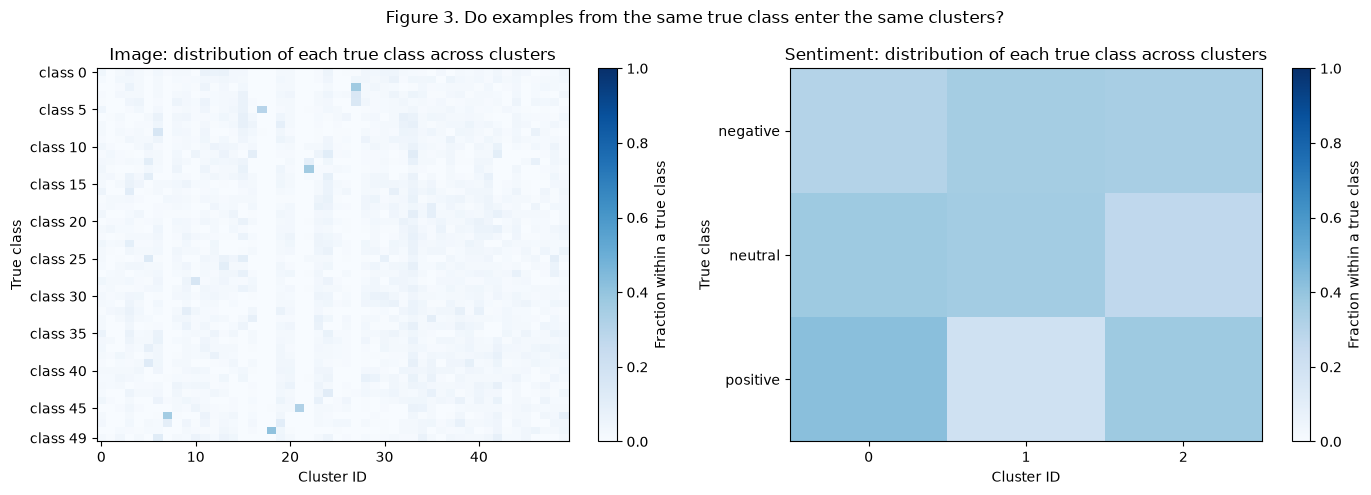

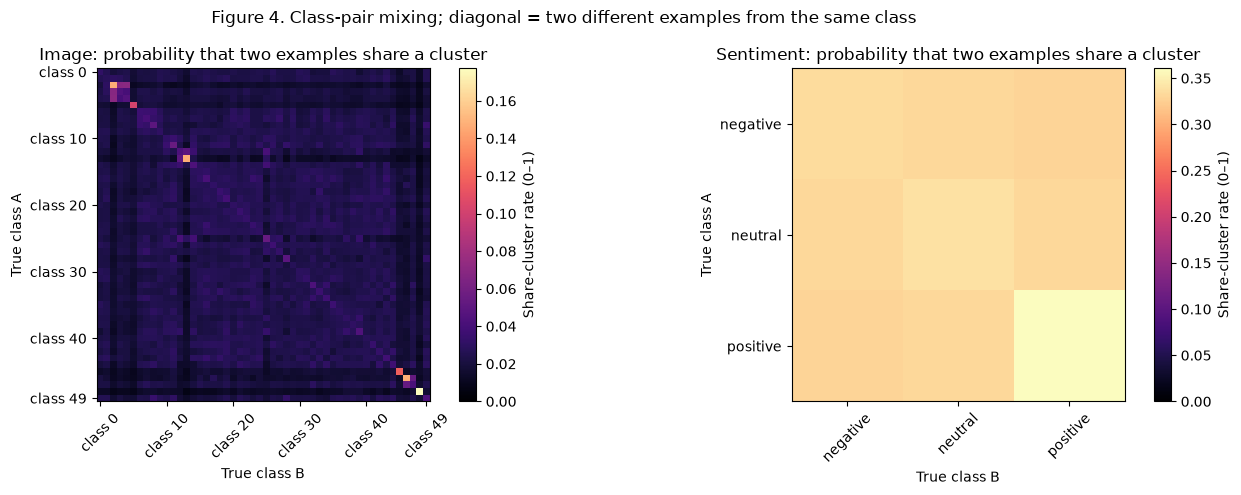

### Table 6. Different-class pairs most frequently assigned to the same cluster

Class A,Class B,Share-cluster rate,Co-clustered pairs
class 2,class 4,6.96%,7129
class 2,class 3,6.87%,7038
class 46,class 47,5.36%,5492
class 12,class 13,4.97%,5085
class 12,class 25,4.11%,4211
Class A,Class B,Share-cluster rate,Co-clustered pairs
negative,neutral,33.21%,3400816
neutral,positive,33.15%,3394494
negative,positive,32.83%,3361760


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task in zip(axes, ['image', 'sentiment']):
    counts = reference[task]['fit']['counts'].to_numpy(float)
    totals = reference[task]['totals']
    fractions = np.divide(counts, totals[None, :], out=np.zeros_like(counts), where=totals[None, :]>0).T
    im = ax.imshow(fractions, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    classes = cluster_data[task]['classes']
    ticks = list(range(classes)) if classes <= 10 else list(range(0, classes, 5)) + [classes-1]
    labels = [class_name(task, i) for i in ticks]
    ax.set(title=f'{task.capitalize()}: distribution of each true class across clusters',
           xlabel='Cluster ID', ylabel='True class', yticks=ticks, yticklabels=labels)
    if REFERENCE_K[task] <= 10:
        ax.set_xticks(range(REFERENCE_K[task]))
    fig.colorbar(im, ax=ax, label='Fraction within a true class')
fig.suptitle('Figure 3. Do examples from the same true class enter the same clusters?')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task in zip(axes, ['image', 'sentiment']):
    rates = reference[task]['pair_rates']
    classes = cluster_data[task]['classes']
    # Each panel has its own labeled scale: a random pair shares a cluster more often when k is smaller.
    im = ax.imshow(rates, cmap='magma', vmin=0, vmax=float(rates.max()), aspect='equal')
    ticks = list(range(classes)) if classes <= 10 else list(range(0, classes, 10)) + [classes-1]
    labels = [class_name(task, i) for i in ticks]
    ax.set(title=f'{task.capitalize()}: probability that two examples share a cluster',
           xlabel='True class B', ylabel='True class A', xticks=ticks, xticklabels=labels,
           yticks=ticks, yticklabels=labels)
    ax.tick_params(axis='x', rotation=45)
    fig.colorbar(im, ax=ax, label='Share-cluster rate (0–1)')
fig.suptitle('Figure 4. Class-pair mixing; diagonal = two different examples from the same class')
fig.tight_layout()
plt.show()
paired_tables('Table 6. Different-class pairs most frequently assigned to the same cluster', pair_tables,
              {'Share-cluster rate': '{:.2%}'})


### Does k have to equal the number of classes?
The class count is a useful reference, but k-Means groups geometric patterns without learning the class labels.
One class can have several patterns, and different classes can overlap. Changing k tests this assumption.
Compare **inertia** (compactness), **purity**, and **Adjusted Rand Index (ARI)** (agreement with true classes,
adjusted for chance: 1 means perfect agreement; around 0 means chance-level agreement).
Purity can increase simply by splitting groups into smaller pieces, so inspect ARI alongside it.
The dotted lines mark the reference class counts, not a guarantee that those k values are best.


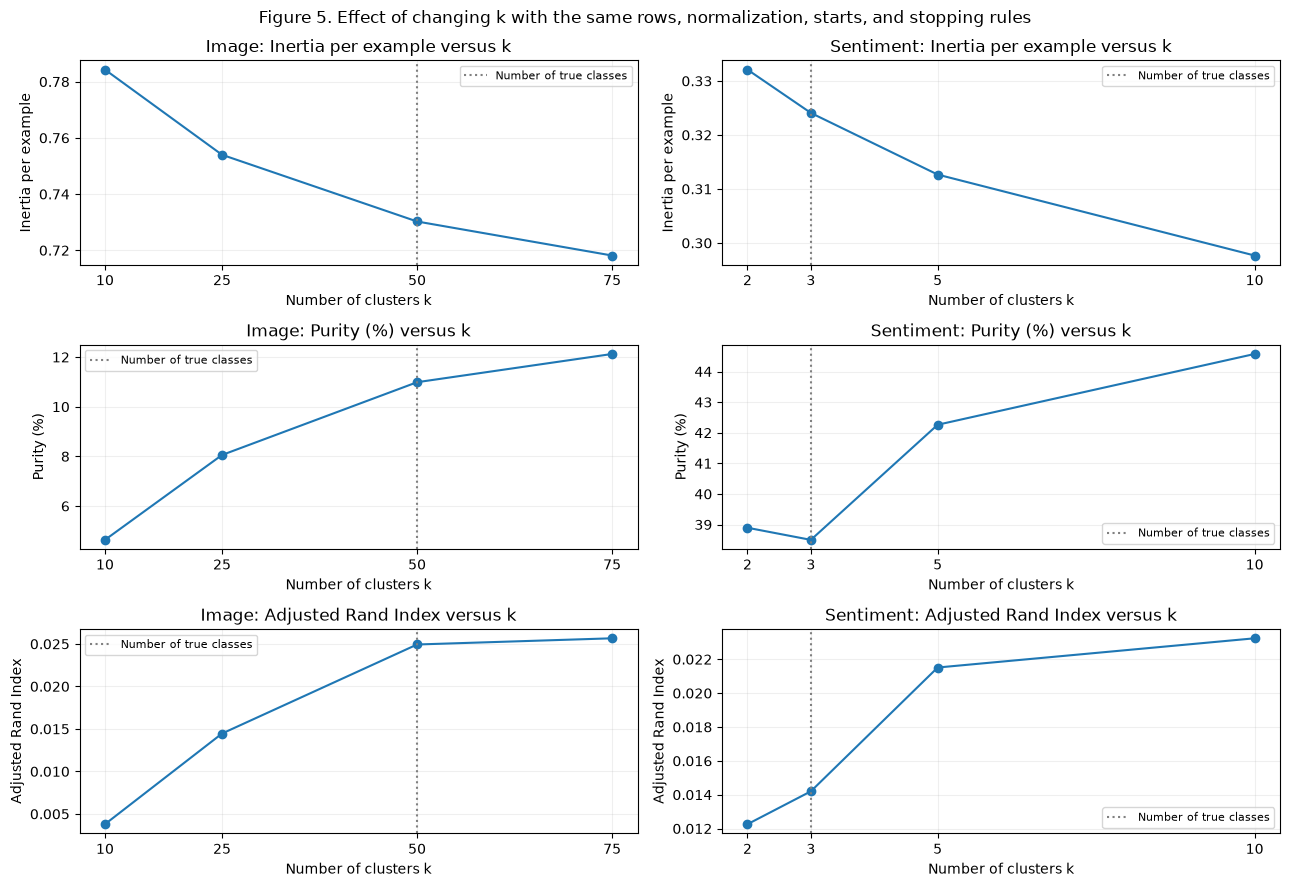

### Table 7. Results for each tested number of clusters

k,inertia,inertia_per_example,purity,ARI,iterations,converged
10,12548.580,0.7843,4.64%,0.0038,43,True
25,12063.840,0.7540,8.06%,0.0145,60,True
50,11684.029,0.7303,10.99%,0.0249,51,True
75,11490.193,0.7181,12.12%,0.0257,47,True
k,inertia,inertia_per_example,purity,ARI,iterations,converged
2,3188.106,0.3321,38.90%,0.0123,28,True
3,3111.137,0.3241,38.50%,0.0142,50,True
5,3001.556,0.3127,42.26%,0.0215,23,True
10,2857.624,0.2977,44.57%,0.0232,70,True


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for column, task in enumerate(['image', 'sentiment']):
    table = cluster_results[cluster_results.task == task].sort_values('k')
    for row, metric, ylabel in [(0, 'inertia_per_example', 'Inertia per example'),
                                (1, 'purity', 'Purity (%)'), (2, 'ARI', 'Adjusted Rand Index')]:
        ax = axes[row, column]
        multiplier = 100 if metric == 'purity' else 1
        ax.plot(table.k, multiplier*table[metric], 'o-')
        ax.axvline(REFERENCE_K[task], color='gray', linestyle=':', label='Number of true classes')
        ax.set(title=f'{task.capitalize()}: {ylabel} versus k', xlabel='Number of clusters k',
               ylabel=ylabel, xticks=CLUSTER_K[task])
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
fig.suptitle('Figure 5. Effect of changing k with the same rows, normalization, starts, and stopping rules')
fig.tight_layout()
plt.show()
paired_tables('Table 7. Results for each tested number of clusters',
              {task: cluster_results[cluster_results.task == task].drop(columns='task')
               for task in ['image', 'sentiment']},
              {'inertia': '{:.3f}', 'inertia_per_example': '{:.4f}', 'purity': '{:.2%}', 'ARI': '{:.4f}'})


### Presentation checklist
1. **Method:** k-NN retrieves similar training rows; k-Means groups rows without labels.
2. **Fair comparison:** both tasks use the team's fixed stratified split; preprocessing fits training rows only.
3. **Main improvement:** square-root normalization changes image similarity; PCA whitening changes sentiment similarity.
4. **Trade-off:** small k is sensitive to individual examples; large k smooths predictions and can erase local detail.
6. **Clustering:** explain the size/composition table; clusters need not match the true classes.
7. **Limits:** selecting among many settings can overstate validation performance; hidden-test accuracy is unknown.

**Reproduction:** run all cells with the supplied competition CSVs. Tables and plots stay in the notebook;
only the two test-prediction CSVs are saved in `part_b` under Kaggle's output directory.
**Assistance:** prepared with Codex; verify the code and be able to explain each step.